In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df=pd.read_csv("/content/student_exam_performance.csv")
df.head(2)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High


# Pearson correlation

In [ ]:
pearson_corr,P_value=pearsonr(df['study_hours_per_day'],df['exam_score'])
print("p value:",P_value,"\ncorrelation:",pearson_corr)

p value: 0.0 
correlation: 0.36324309053382814


# Spearmen correlation

In [ ]:
spearmen_corr,P_value=spearmanr(df['study_hours_per_day'],df['exam_score'])
print("p value:",P_value,"\ncorrelation:",spearmen_corr)

p value: 0.0 
correlation: 0.3405575846275944


# To create the Heat map and matrix

In [34]:
  numeric_df=df.select_dtypes(['float64','int64'])
  numeric_df.head(2)

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
0,20,78.36,2.95,81.49,65.18,4.94,2.63,0,1.75,8,...,0.93,10,1,2.15,27,95,86,NaN,9.39,90.40
1,17,73.40,2.89,NaN,76.53,3.42,2.64,0,1.97,10,...,0.21,8,1,4.37,4,100,86,87.17,6.31,86.21


In [35]:
pearson_matrix=numeric_df.corr(method='pearson')
spearmen_matrix=numeric_df.corr(method='spearman')
pearson_matrix
spearmen_matrix

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
age,1.000000,-0.000952,-0.001683,-0.000676,-0.000465,-0.000994,-0.002045,0.000038,0.003489,0.002097,...,-0.002524,-0.001727,0.001243,-0.003403,-0.003385,-0.001020,-0.003101,0.002660,0.001861,-0.003271
previous_exam_score,-0.000952,1.000000,0.945043,0.036182,0.017107,0.001537,0.000437,0.003475,-0.003937,-0.000758,...,-0.001269,0.001372,0.000157,0.001357,0.002698,0.002535,0.467284,0.004795,-0.000833,0.479357
previous_gpa,-0.001683,0.945043,1.000000,0.038297,0.017585,0.000912,-0.000012,-0.001724,-0.005402,-0.002309,...,-0.001783,0.001538,-0.000088,0.001027,0.000827,0.002456,0.441697,0.003133,0.001341,0.453099
attendance_percentage,-0.000676,0.036182,0.038297,1.000000,0.380765,-0.000384,-0.001985,0.005273,0.005097,-0.003537,...,0.000003,-0.002334,-0.003550,-0.005801,-0.003892,0.003049,0.157348,0.001999,-0.003795,0.161301
assignment_completion_rate,-0.000465,0.017107,0.017585,0.380765,1.000000,0.385814,0.368109,0.001083,0.005008,0.127620,...,-0.005219,-0.000872,0.002813,0.002008,0.000083,-0.003158,0.203431,-0.001981,-0.002837,0.209563
study_hours_per_day,-0.000994,0.001537,0.000912,-0.000384,0.385814,1.000000,0.958645,-0.002093,0.000612,0.315449,...,-0.002755,-0.001047,-0.001627,0.004231,0.000464,-0.002732,0.331688,0.004739,-0.003588,0.340558
self_study_hours,-0.002045,0.000437,-0.000012,-0.001985,0.368109,0.958645,1.000000,-0.000262,0.000566,0.301283,...,-0.001961,0.000342,-0.001867,0.003372,0.000434,-0.001516,0.315956,0.003639,-0.000673,0.324117
private_tuition,0.000038,0.003475,-0.001724,0.005273,0.001083,-0.002093,-0.000262,1.000000,0.003911,0.000656,...,0.000250,-0.003811,0.001724,-0.001907,-0.003471,0.001007,0.003646,0.003001,-0.002156,0.003117
online_learning_hours,0.003489,-0.003937,-0.005402,0.005097,0.005008,0.000612,0.000566,0.003911,1.000000,-0.002948,...,0.003596,0.002537,-0.008129,0.002450,0.001929,-0.008037,-0.004016,-0.003368,0.000826,-0.003176
practice_tests_completed,0.002097,-0.000758,-0.002309,-0.003537,0.127620,0.315449,0.301283,0.000656,-0.002948,1.000000,...,0.003513,0.002498,-0.002877,-0.002017,0.005560,0.000456,0.291548,0.003320,-0.001855,0.299036


# Heat map of Pearson_matrix

Text(0.5, 1.0, 'Pearson Correlation')

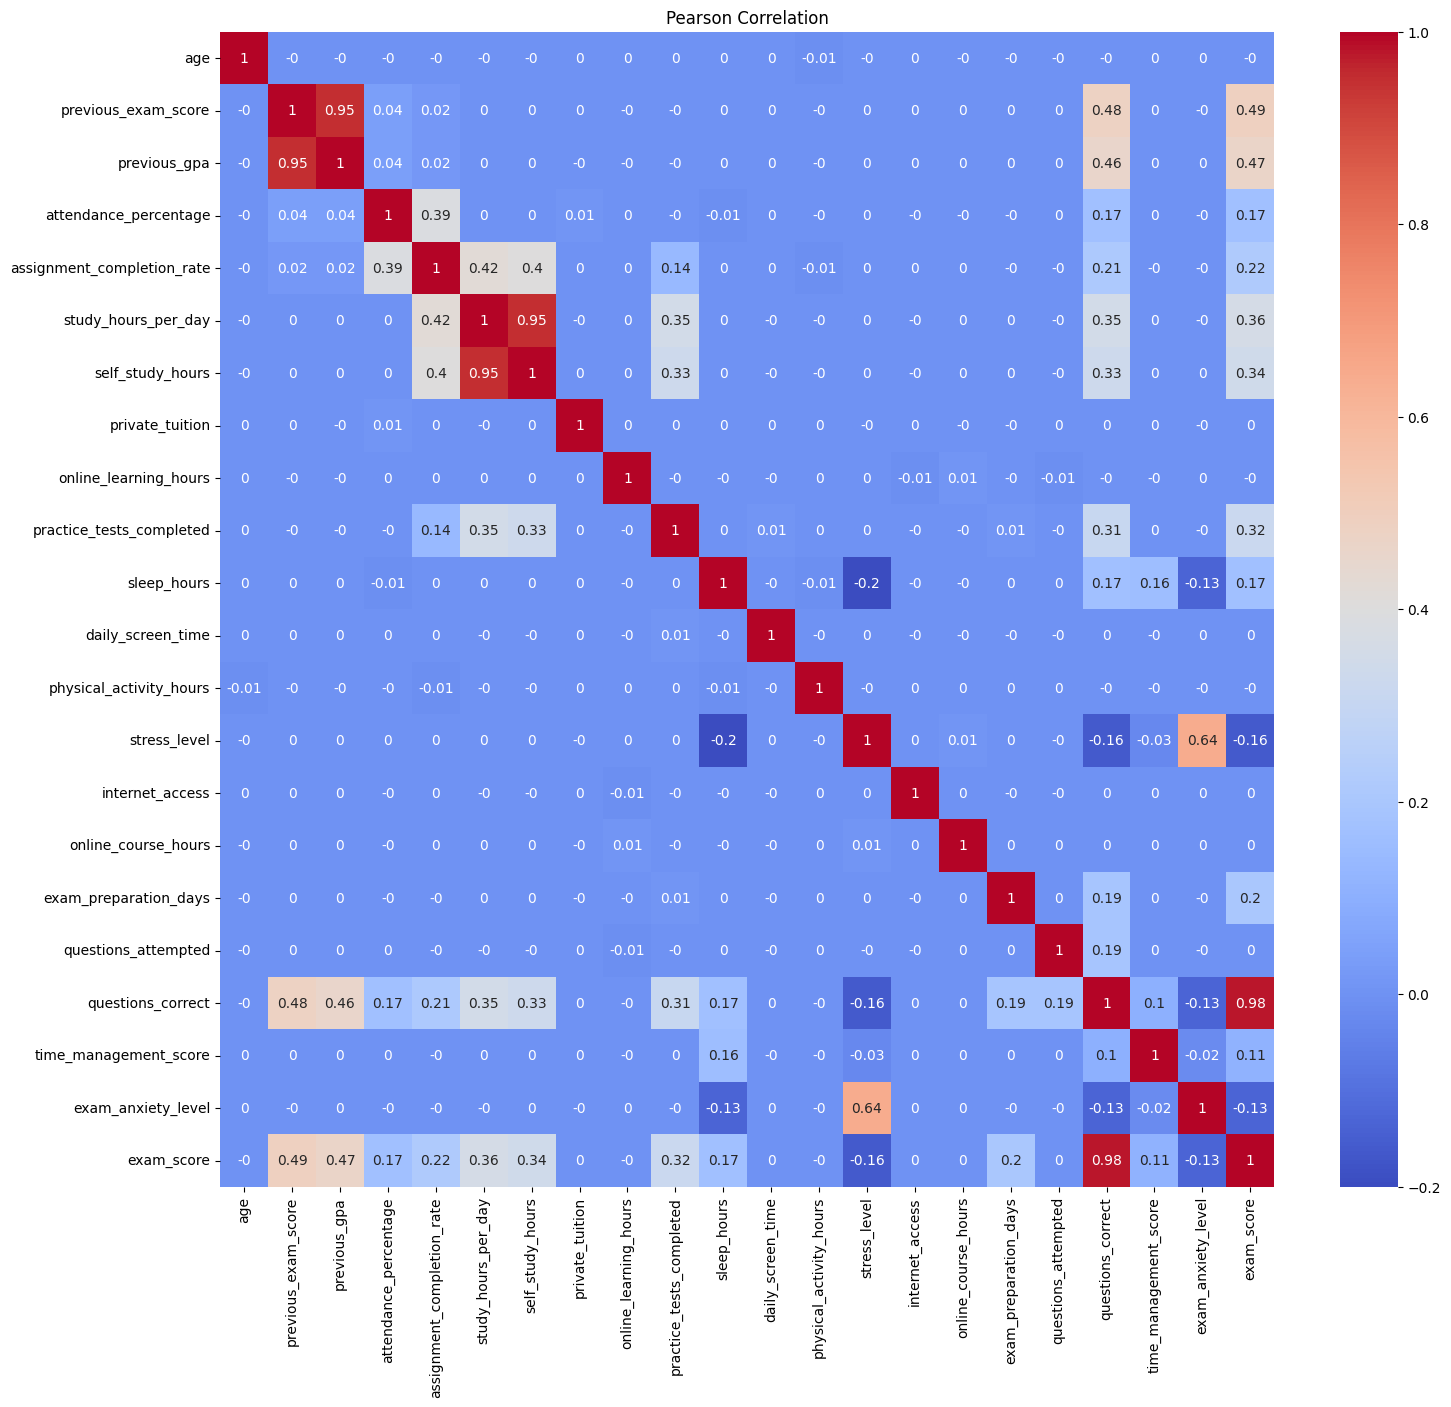

In [15]:
plt.figure(figsize=(17, 15))
sns.heatmap(pearson_matrix.round(2), annot =True,  cmap='coolwarm')
plt.title("Pearson Correlation")

# Scatter matrix for spearmen_matrix

<Figure size 1700x1500 with 0 Axes>

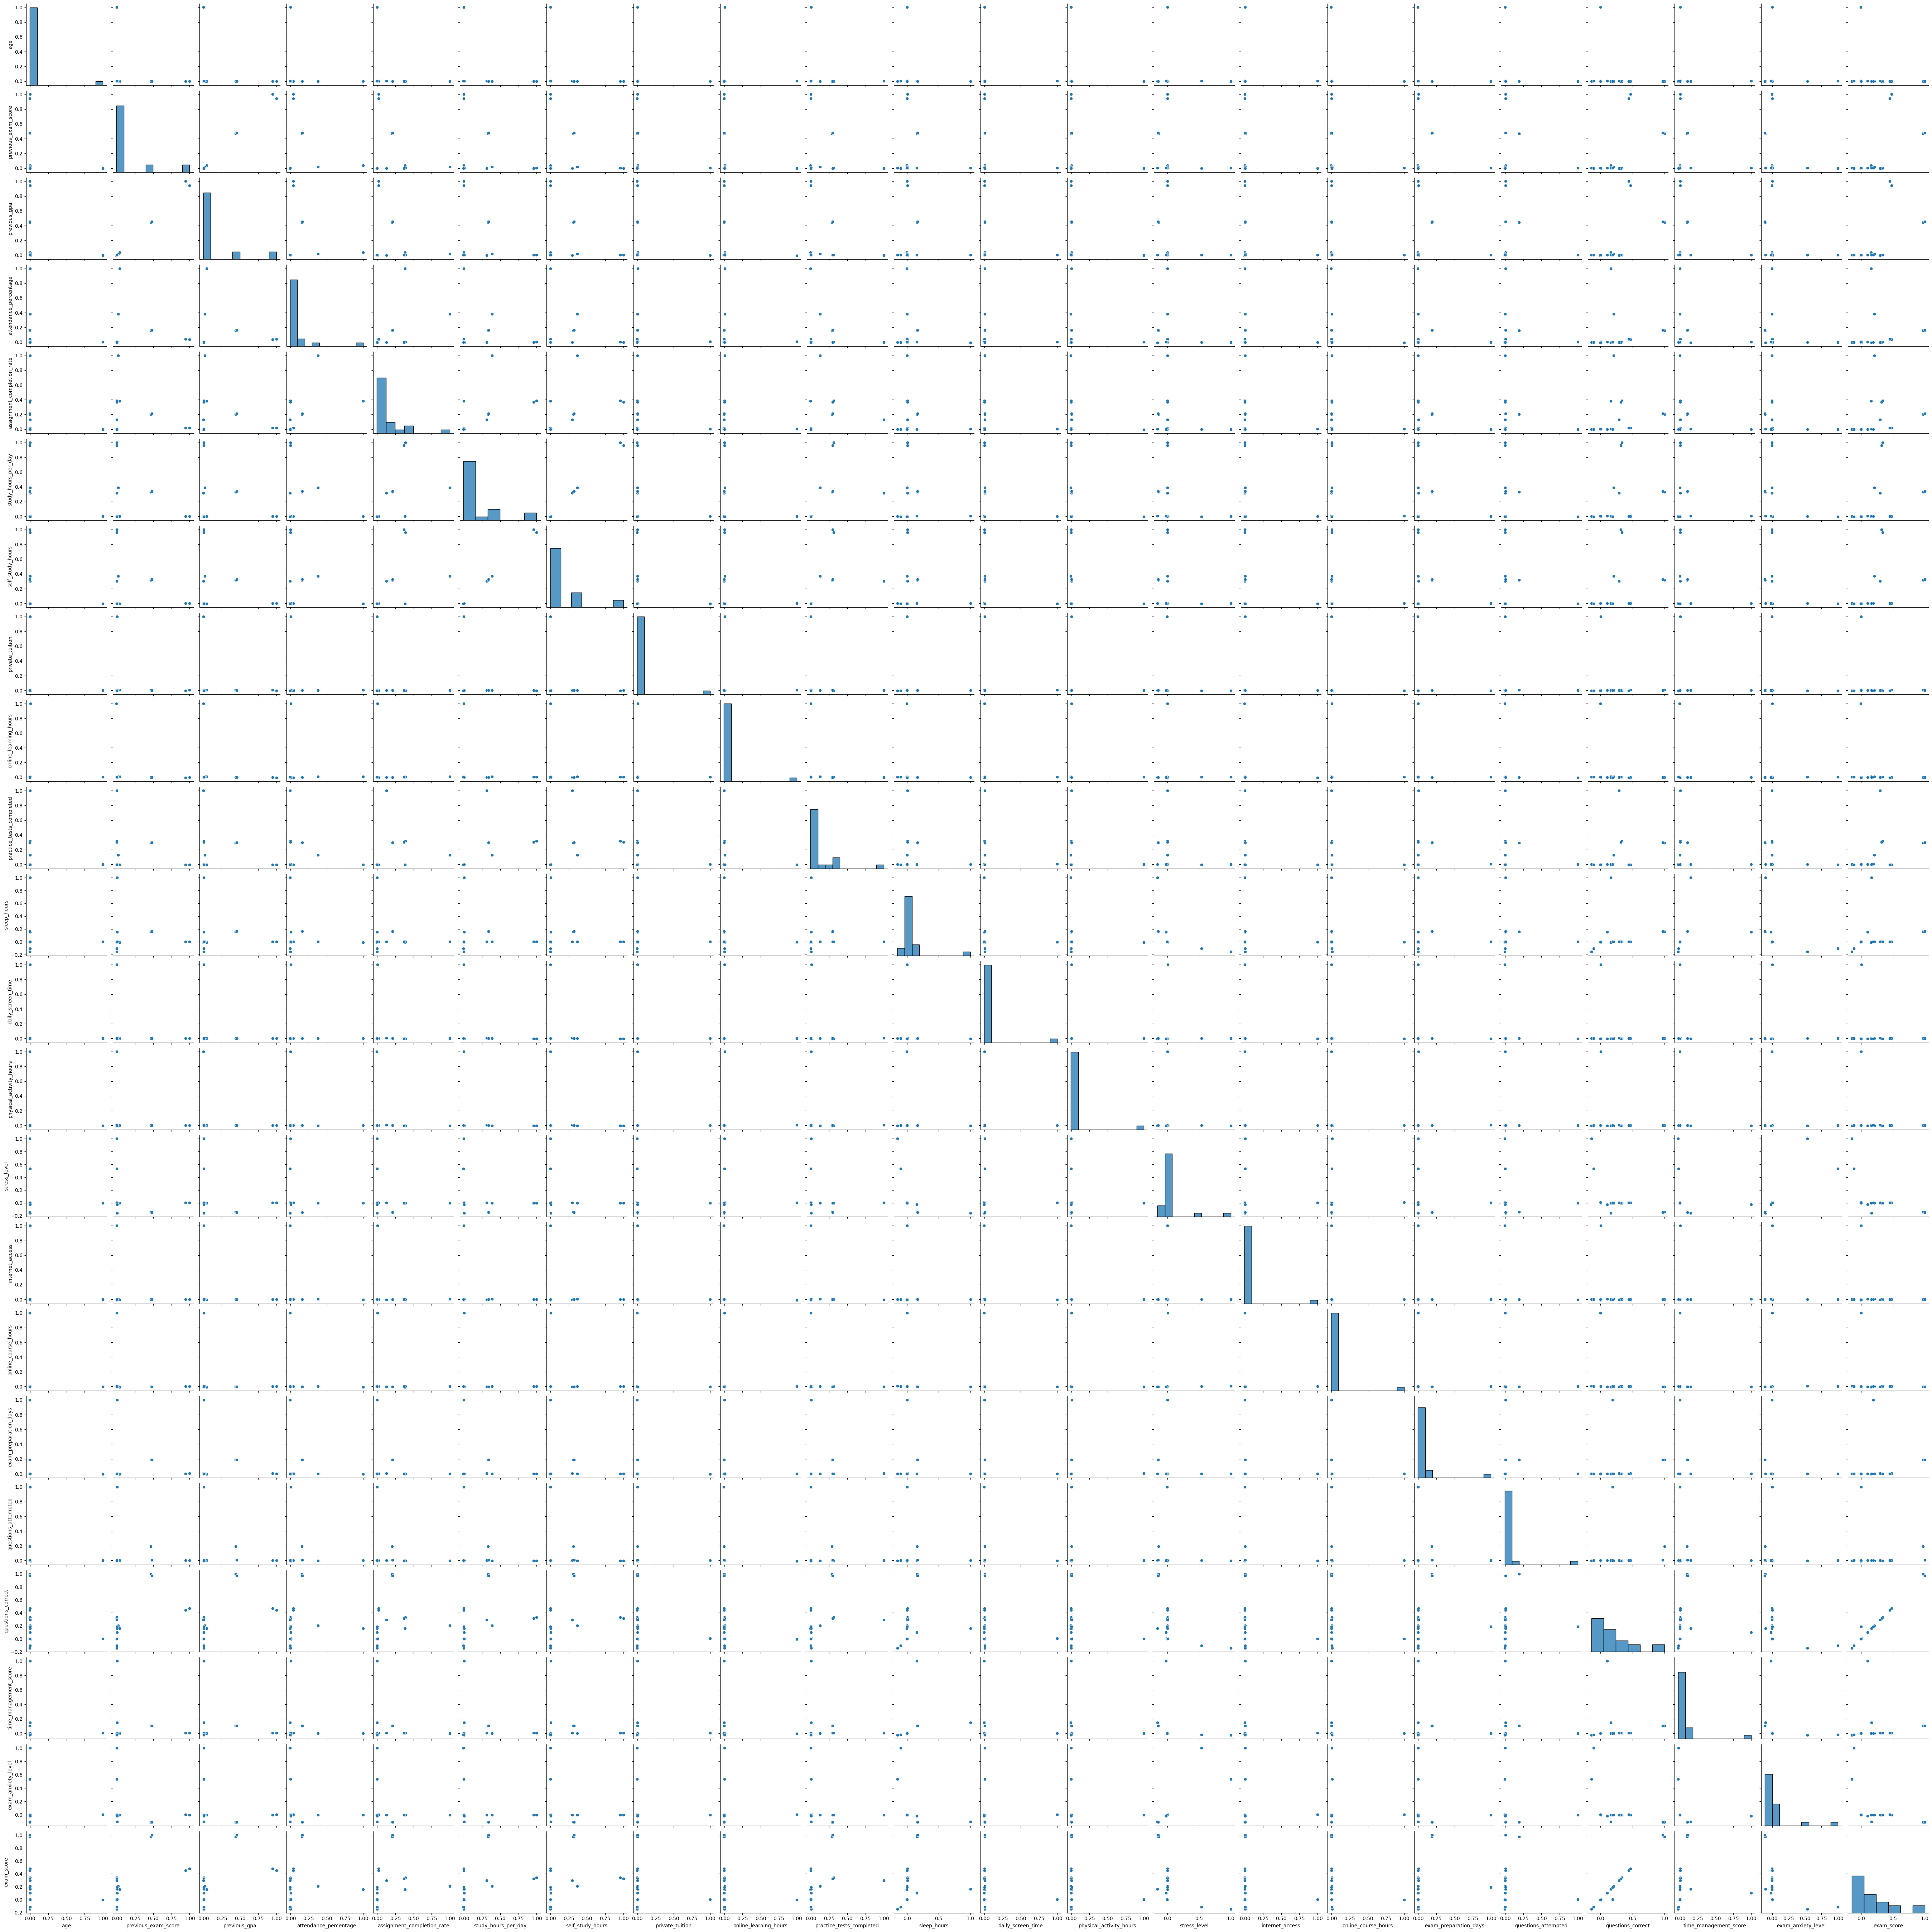

In [36]:
plt.figure(figsize=(17, 15))
sns.pairplot(spearmen_matrix)

# Lets Train the model using simple linear regression

In [21]:
x=numeric_df1.drop('exam_score',axis=1)
y=numeric_df1['exam_score']

x_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

model=LinearRegression()
model.fit(x_train,y_train)

y_pred=model.predict(X_test)

# Findin r^2,Mean absolute error, and Root mean square error

In [27]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("R-squared:", r2,"\nMean Absolute Error:", mae,"\nRoot Mean Squared Error:", rmse)


R-squared: 0.9869942205797743 
Mean Absolute Error: 1.4305369534686685 
Root Mean Squared Error: 1.7980714770520303


# Plotting scatter plot

Text(0.5, 1.0, 'residual plot')

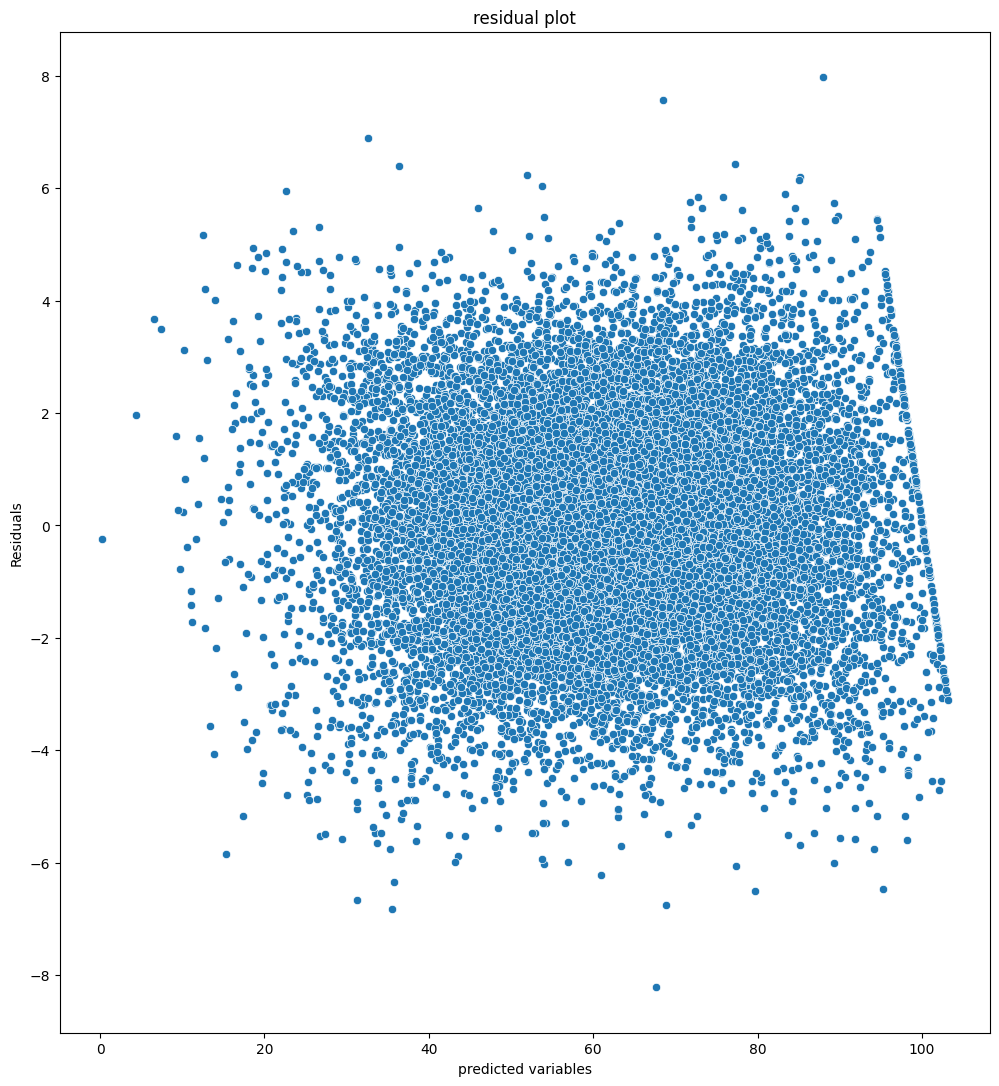

In [31]:
residuals=y_test-y_pred

plt.figure(figsize=(12,13))

sns.scatterplot(x=y_pred,y=residuals)
plt.xlabel("predicted variables")
plt.ylabel("Residuals")
plt.title("residual plot")

# Distribution of residual

Text(0.5, 1.0, 'Distribution of residuals')

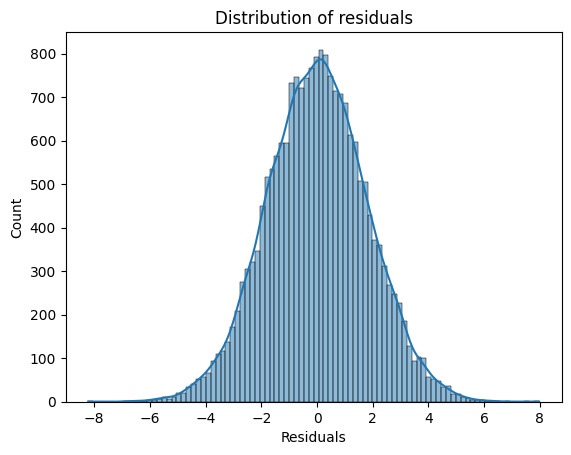

In [32]:
sns.histplot(residuals,kde=True)
plt.xlabel("Residuals")
plt.title("Distribution of residuals")
